In [85]:
print("¡Python está funcionando correctamente!")

¡Python está funcionando correctamente!


# UNIVERSIDAD AUTÓNOMA DEL ESTADO DE MÉXICO

## Centro Universitario UAEM Zumpango

 Ingeniería en Computación

Investigación de Operaciones

Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook

Ruta Crítica (PERT/CPM)

Desarrollo e implementación de un sistema gestor escolar


- Alvares Lugardo Laura Selene
- Rosales Gonzales Imanol
- Garcia cerritos Jan Carlos


19 de noviembre de 2026

# 1. Descripción y planteamiento del problema

## Desarrollo e implementación de un sistema escolar

Se plantea el desarrollo de un sistema escolar cuyo propósito es facilitar la administración de los procesos de inscripción, registro de alumnos y consulta de información académica dentro de una institución educativa.

Para llevar a cabo este proyecto es necesario realizar diferentes actividades, como el análisis de requerimientos, diseño del sistema, creación de la base de datos, desarrollo de interfaces, integración de módulos, pruebas y finalmente la implementación.

Algunas actividades dependen de que otras hayan finalizado para poder comenzar, por lo que es importante establecer una secuencia de trabajo y conocer cuánto tiempo requiere cada una.

Mediante el método de la ruta crítica (PERT/CPM) se analizarán las actividades del proyecto, sus duraciones y relaciones de precedencia, con el propósito de calcular los tiempos de inicio y finalización tempranos y tardíos, determinar las holguras e identificar la ruta crítica.

De esta manera, será posible conocer la duración mínima estimada del proyecto y reconocer cuáles actividades no pueden retrasarse sin afectar su fecha de finalización.

# 2. Definición de actividades y precedencias

Para aplicar el método PERT/CPM se establecen diez actividades necesarias para desarrollar e implementar el sistema escolar. A cada actividad se le asigna una duración estimada en días y se identifican sus actividades predecesoras.

| Clave | Actividad | Duración (días) | Predecesora |
|:---:|---|:---:|:---:|
| A | Análisis de requerimientos | 2 | Ninguna |
| B | Diseño del sistema | 3 | A |
| C | Diseño de base de datos | 2 | B |
| D | Diseño de interfaces | 2 | B |
| E | Desarrollo de base de datos | 4 | C |
| F | Desarrollo de interfaces | 3 | D |
| G | Integración de módulos | 2 | E, F |
| H | Pruebas del sistema | 3 | G |
| I | Corrección de errores | 2 | H |
| J | Implementación del sistema | 2 | I |

Las duraciones representan días de trabajo estimados. Las actividades B, C y D dependen de la finalización de sus respectivas predecesoras. Asimismo, la integración de módulos (G) solamente puede comenzar cuando hayan terminado tanto el desarrollo de la base de datos (E) como el desarrollo de interfaces (F).

Esta relación de dependencia permitirá construir la red del proyecto y determinar la secuencia de actividades que establece su duración total.

# 3. Formulación matemática del modelo PERT/CPM

Para determinar la ruta crítica se utilizará el método CPM (Critical Path Method), que permite calcular los tiempos de ejecución de cada actividad mediante dos recorridos en la red.

**a) Recorrido hacia adelante: tiempos tempranos**

- Inicio temprano (IT): momento más pronto en que puede iniciar una actividad.
- Fin temprano (FT): momento más pronto en que puede terminar una actividad.

\[
FT = IT + Duración
\]

\[
IT = \max(FT \text{ de las predecesoras})
\]

**b) Recorrido hacia atrás: tiempos tardíos**

- Fin tardío (FTa): momento más tarde en que puede finalizar una actividad sin retrasar el proyecto.
- Inicio tardío (ITa): momento más tarde en que puede comenzar una actividad sin retrasar el proyecto.

\[
ITa = FTa - Duración
\]

\[
FTa = \min(ITa \text{ de las sucesoras})
\]

**c) Cálculo de holgura**

La holgura representa el tiempo que una actividad puede retrasarse sin afectar la duración total del proyecto.

\[
Holgura = ITa - IT
\]

**d) Identificación de la ruta crítica**

Las actividades cuya holgura es igual a cero forman parte de la ruta crítica.

\[
Holgura = 0
\]

La duración total del proyecto estará determinada por la secuencia de actividades críticas.

# 4. Importación de bibliotecas

Para desarrollar el modelo de ruta crítica se utilizarán diferentes bibliotecas de Python que permitirán organizar los datos, construir la red de actividades, realizar los cálculos y representar gráficamente el proyecto.

- **NetworkX:** permite crear y analizar grafos que representan las actividades y sus relaciones de precedencia.
- **Matplotlib:** permite generar gráficas para visualizar la red del proyecto y la ruta crítica.
- **Pandas:** facilita la organización y presentación de los resultados mediante tablas.
- **NumPy:** proporciona herramientas para realizar operaciones numéricas.

In [86]:
# Importación de bibliotecas

import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("Bibliotecas importadas correctamente.")

Bibliotecas importadas correctamente.


# 5. Definición de los datos del proyecto

Se definirán las diez actividades del proyecto mediante una estructura de datos que contendrá su clave de identificación, nombre, duración estimada y actividades predecesoras.

Esta información será utilizada posteriormente para construir el grafo, calcular los tiempos tempranos y tardíos, y determinar las holguras de cada actividad.

In [87]:
# Definición de las actividades del proyecto

actividades = {
    'A': {'nombre': 'Análisis de requerimientos', 'duracion': 2, 'predecesoras': []},
    'B': {'nombre': 'Diseño del sistema', 'duracion': 3, 'predecesoras': ['A']},
    'C': {'nombre': 'Diseño de base de datos', 'duracion': 2, 'predecesoras': ['B']},
    'D': {'nombre': 'Diseño de interfaces', 'duracion': 2, 'predecesoras': ['B']},
    'E': {'nombre': 'Desarrollo de base de datos', 'duracion': 4, 'predecesoras': ['C']},
    'F': {'nombre': 'Desarrollo de interfaces', 'duracion': 3, 'predecesoras': ['D']},
    'G': {'nombre': 'Integración de módulos', 'duracion': 2, 'predecesoras': ['E', 'F']},
    'H': {'nombre': 'Pruebas del sistema', 'duracion': 3, 'predecesoras': ['G']},
    'I': {'nombre': 'Corrección de errores', 'duracion': 2, 'predecesoras': ['H']},
    'J': {'nombre': 'Implementación del sistema', 'duracion': 2, 'predecesoras': ['I']}
}

print("Actividades registradas:", len(actividades))

Actividades registradas: 10


# 6. Construcción de la red de actividades

Se utilizará la biblioteca NetworkX para construir un grafo dirigido, en el cual cada nodo representará una actividad del proyecto y cada conexión indicará una relación de precedencia.

Las flechas mostrarán el orden en que deben realizarse las actividades. Cuando una actividad tenga más de una predecesora, deberá esperar a que todas hayan finalizado para poder comenzar.

Esta representación permitirá observar la estructura del proyecto y facilitará el cálculo de la ruta crítica.

In [88]:
# Crear un grafo dirigido

G = nx.DiGraph()

# Agregar las actividades como nodos
for clave, datos in actividades.items():
    G.add_node(clave, nombre=datos['nombre'],
               duracion=datos['duracion'])

# Agregar las conexiones según las precedencias
for clave, datos in actividades.items():
    for predecesora in datos['predecesoras']:
        G.add_edge(predecesora, clave)

print("Grafo construido correctamente.")
print("Número de nodos:", G.number_of_nodes())
print("Número de conexiones:", G.number_of_edges())

Grafo construido correctamente.
Número de nodos: 10
Número de conexiones: 10


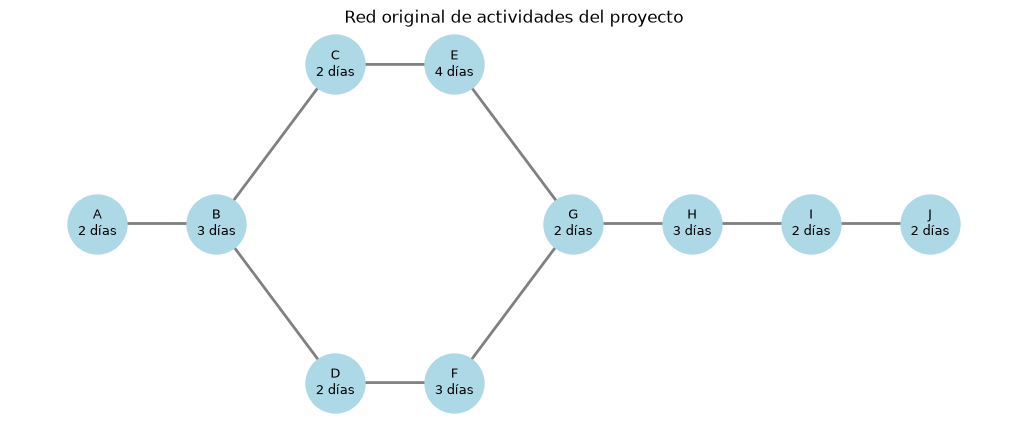

In [89]:
# Posiciones de los nodos en la gráfica
pos = {
    'A': (0, 2),
    'B': (1, 2),
    'C': (2, 3),
    'D': (2, 1),
    'E': (3, 3),
    'F': (3, 1),
    'G': (4, 2),
    'H': (5, 2),
    'I': (6, 2),
    'J': (7, 2)
}

# Dibujar la red original
plt.figure(figsize=(13, 5))

nx.draw_networkx_nodes(
    G, pos, node_color='lightblue',
    node_size=1800
)

nx.draw_networkx_edges(
    G, pos, edge_color='gray',
    arrows=True, arrowsize=20,
    width=2
)



# Mostrar la duración de cada actividad
etiquetas = {
    nodo: f"{nodo}\n{G.nodes[nodo]['duracion']} días"
    for nodo in G.nodes()
}

nx.draw_networkx_labels(
    G, pos, labels=etiquetas,
    font_size=9
)

plt.title("Red original de actividades del proyecto")
plt.axis('off')
plt.show()

# 7. Cálculo de tiempos tempranos (recorrido hacia adelante)

El recorrido hacia adelante permite determinar el inicio temprano (IT) y el fin temprano (FT) de cada actividad.

Para realizar este cálculo se siguen las siguientes reglas:

- La primera actividad comienza en el tiempo cero.
- El inicio temprano de una actividad corresponde al mayor fin temprano de sus actividades predecesoras.
- El fin temprano se obtiene sumando la duración de la actividad a su inicio temprano.

Las fórmulas utilizadas son:

\[
IT = \max(FT \text{ de las predecesoras})
\]

\[
FT = IT + Duración
\]

Este procedimiento se realiza siguiendo el orden de las actividades, desde el inicio hasta el final del proyecto.

In [90]:
# Obtener el orden de ejecución de las actividades

orden = list(nx.topological_sort(G))

print("Orden de las actividades:")
print(orden)

Orden de las actividades:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']


In [91]:
# Inicializar diccionario de tiempos tempranos

tiempos = {}

# Recorrido hacia adelante
for actividad in orden:

    predecesoras = list(G.predecessors(actividad))

    # Calcular inicio temprano
    if len(predecesoras) == 0:
        IT = 0
    else:
        IT = max(tiempos[p]['FT'] for p in predecesoras)

    # Calcular fin temprano
    FT = IT + actividades[actividad]['duracion']

    tiempos[actividad] = {
        'IT': IT,
        'FT': FT
    }

    print(f"Actividad {actividad}: IT = {IT}, FT = {FT}")

Actividad A: IT = 0, FT = 2
Actividad B: IT = 2, FT = 5
Actividad C: IT = 5, FT = 7
Actividad D: IT = 5, FT = 7
Actividad E: IT = 7, FT = 11
Actividad F: IT = 7, FT = 10
Actividad G: IT = 11, FT = 13
Actividad H: IT = 13, FT = 16
Actividad I: IT = 16, FT = 18
Actividad J: IT = 18, FT = 20


# 8. Cálculo de tiempos tardíos (recorrido hacia atrás)

El recorrido hacia atrás permite determinar el inicio tardío (ITa) y el fin tardío (FTa) de cada actividad.

Estos valores indican el momento máximo en que puede comenzar o terminar una actividad sin provocar un retraso en la duración total del proyecto.

Para realizar el cálculo se utilizan las siguientes reglas:

- El fin tardío de la última actividad corresponde a la duración total del proyecto.
- El inicio tardío se obtiene restando la duración de la actividad a su fin tardío.
- Para las actividades que tienen sucesoras, el fin tardío corresponde al menor inicio tardío de sus actividades sucesoras.

Las fórmulas utilizadas son:

\[
ITa = FTa - Duración
\]

\[
FTa = \min(ITa \text{ de las sucesoras})
\]

El procedimiento comienza desde la última actividad y continúa en sentido inverso hasta llegar a la primera.

In [92]:
# Inicializar los tiempos tardíos

tiempos_tardios = {}

# Duración total del proyecto
duracion_proyecto = max(
    datos['FT'] for datos in tiempos.values()
)

print("Duración total del proyecto:", duracion_proyecto, "días")

# Recorrido hacia atrás
for actividad in reversed(orden):

    sucesoras = list(G.successors(actividad))

    # Calcular fin tardío
    if len(sucesoras) == 0:
        FTa = duracion_proyecto
    else:
        FTa = min(
            tiempos_tardios[s]['ITa']
            for s in sucesoras
        )

    # Calcular inicio tardío
    ITa = FTa - actividades[actividad]['duracion']

    tiempos_tardios[actividad] = {
        'ITa': ITa,
        'FTa': FTa
    }

    print(f"Actividad {actividad}: ITa = {ITa}, FTa = {FTa}")

Duración total del proyecto: 20 días
Actividad J: ITa = 18, FTa = 20
Actividad I: ITa = 16, FTa = 18
Actividad H: ITa = 13, FTa = 16
Actividad G: ITa = 11, FTa = 13
Actividad F: ITa = 8, FTa = 11
Actividad E: ITa = 7, FTa = 11
Actividad D: ITa = 6, FTa = 8
Actividad C: ITa = 5, FTa = 7
Actividad B: ITa = 2, FTa = 5
Actividad A: ITa = 0, FTa = 2


# 9. Cálculo de holguras

La holgura representa el tiempo que una actividad puede retrasarse sin modificar la duración total del proyecto.

Para calcularla se resta el inicio temprano al inicio tardío de cada actividad.

\[
Holgura = ITa - IT
\]

Cuando una actividad tiene una holgura igual a cero, significa que no puede retrasarse sin afectar la fecha de finalización del proyecto.

Las actividades con holgura cero forman parte de la ruta crítica.

In [93]:
# Calcular la holgura de cada actividad

for actividad in orden:

    IT = tiempos[actividad]['IT']
    ITa = tiempos_tardios[actividad]['ITa']

    holgura = ITa - IT

    tiempos[actividad]['Holgura'] = holgura

    print(f"Actividad {actividad}: Holgura = {holgura} días")

Actividad A: Holgura = 0 días
Actividad B: Holgura = 0 días
Actividad C: Holgura = 0 días
Actividad D: Holgura = 1 días
Actividad E: Holgura = 0 días
Actividad F: Holgura = 1 días
Actividad G: Holgura = 0 días
Actividad H: Holgura = 0 días
Actividad I: Holgura = 0 días
Actividad J: Holgura = 0 días


Las actividades D y F presentan una holgura de un día, lo que significa que pueden retrasarse hasta un día sin modificar la duración total del proyecto.

Por otra parte, las actividades A, B, C, E, G, H, I y J tienen una holgura igual a cero. Esto indica que cualquier retraso en ellas provocaría un retraso en la finalización del proyecto.

Por lo tanto, estas actividades serán consideradas para identificar la ruta crítica.


# 10. Identificación de la ruta crítica

La ruta crítica está formada por las actividades cuya holgura es igual a cero. Estas actividades representan la secuencia de trabajo que determina la duración total del proyecto.

Para identificarla se revisarán las holguras calculadas anteriormente y se seleccionarán únicamente las actividades que no cuentan con tiempo disponible para retrasarse.

La duración de la ruta crítica se obtiene sumando las duraciones de todas las actividades que la integran.

In [94]:
# Identificar las actividades con holgura igual a cero

ruta_critica = [
    actividad for actividad in orden
    if tiempos[actividad]['Holgura'] == 0
]

# Calcular la duración de la ruta crítica
duracion_critica = sum(
    actividades[actividad]['duracion']
    for actividad in ruta_critica
)

print("Ruta crítica:", " -> ".join(ruta_critica))
print("Duración de la ruta crítica:", duracion_critica, "días")

Ruta crítica: A -> B -> C -> E -> G -> H -> I -> J
Duración de la ruta crítica: 20 días


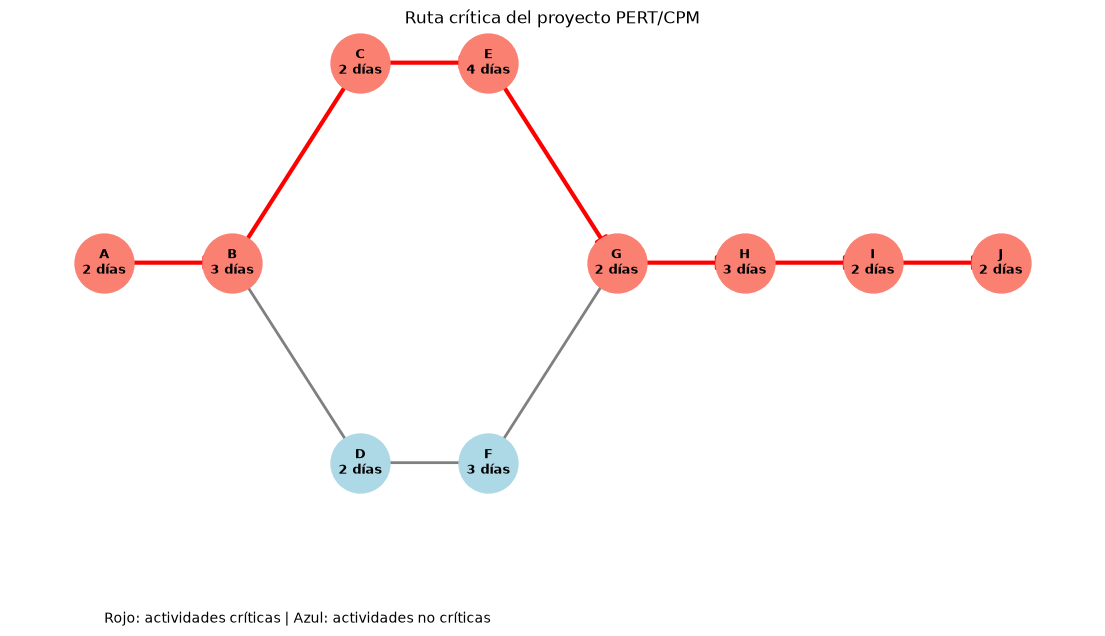

In [95]:
# Separar actividades críticas y no críticas

no_criticas = [
    actividad for actividad in G.nodes()
    if actividad not in ruta_critica
]

# Identificar conexiones críticas
aristas_criticas = [
    (u, v) for u, v in G.edges()
    if u in ruta_critica and v in ruta_critica
]

aristas_no_criticas = [
    (u, v) for u, v in G.edges()
    if (u, v) not in aristas_criticas
]

# Crear gráfica
plt.figure(figsize=(14, 6))

# Dibujar nodos no críticos
nx.draw_networkx_nodes(
    G, pos,
    nodelist=no_criticas,
    node_color='lightblue',
    node_size=1800
)

# Dibujar nodos críticos
nx.draw_networkx_nodes(
    G, pos,
    nodelist=ruta_critica,
    node_color='salmon',
    node_size=1800
)

# Dibujar conexiones no críticas
nx.draw_networkx_edges(
    G, pos,
    edgelist=aristas_no_criticas,
    edge_color='gray',
    arrows=True,
    arrowsize=20,
    width=2
)

# Dibujar conexiones críticas
nx.draw_networkx_edges(
    G, pos,
    edgelist=aristas_criticas,
    edge_color='red',
    arrows=True,
    arrowsize=20,
    width=3
)

# Etiquetas con clave y duración
etiquetas = {
    nodo: f"{nodo}\n{actividades[nodo]['duracion']} días"
    for nodo in G.nodes()
}

nx.draw_networkx_labels(
    G, pos,
    labels=etiquetas,
    font_size=9,
    font_weight='bold'
)

plt.title("Ruta crítica del proyecto PERT/CPM")
plt.text(0, 0.2, "Rojo: actividades críticas | Azul: actividades no críticas",
         fontsize=10)

plt.axis('off')
plt.show()

La ruta crítica identificada está compuesta por las actividades A, B, C, E, G, H, I y J, con una duración total de 20 días.

Las actividades D y F no forman parte de la ruta crítica, ya que presentan una holgura de un día cada una.

Esto significa que el proyecto puede completarse en un tiempo mínimo estimado de 20 días, siempre que las actividades críticas se realicen de acuerdo con los tiempos calculados y no sufran retrasos.

La representación gráfica permite distinguir las actividades que determinan la duración del proyecto de aquellas que cuentan con cierto margen de tiempo.

# 11. Tabla general de resultados

En esta sección se integrarán los resultados obtenidos durante el desarrollo del modelo PERT/CPM.

Se presentarán los tiempos de inicio y finalización tempranos y tardíos, así como las holguras de cada actividad. Esto permitirá comparar los valores calculados e identificar fácilmente las actividades que pertenecen a la ruta crítica.

In [96]:
# Crear la tabla general de resultados

resultados = []

for actividad in orden:

    resultados.append({
        'Actividad': actividad,
        'Nombre': actividades[actividad]['nombre'],
        'Duración': actividades[actividad]['duracion'],
        'IT': tiempos[actividad]['IT'],
        'FT': tiempos[actividad]['FT'],
        'ITa': tiempos_tardios[actividad]['ITa'],
        'FTa': tiempos_tardios[actividad]['FTa'],
        'Holgura': tiempos[actividad]['Holgura'],
        'Crítica': 'Sí' if tiempos[actividad]['Holgura'] == 0 else 'No'
    })

df_resultados = pd.DataFrame(resultados)

display(df_resultados)

,Actividad,Nombre,Duración,IT,FT,ITa,FTa,Holgura,Crítica
0,A,Análisis de requerimientos,2,0,2,0,2,0,Sí
1,B,Diseño del sistema,3,2,5,2,5,0,Sí
2,C,Diseño de base de datos,2,5,7,5,7,0,Sí
3,D,Diseño de interfaces,2,5,7,6,8,1,No
4,E,Desarrollo de base de datos,4,7,11,7,11,0,Sí
5,F,Desarrollo de interfaces,3,7,10,8,11,1,No
6,G,Integración de módulos,2,11,13,11,13,0,Sí
7,H,Pruebas del sistema,3,13,16,13,16,0,Sí
8,I,Corrección de errores,2,16,18,16,18,0,Sí
9,J,Implementación del sistema,2,18,20,18,20,0,Sí


In [97]:
# Resumen general del proyecto

print("RESUMEN DEL PROYECTO")
print("------------------------------")
print("Total de actividades:", len(actividades))
print("Duración total:", duracion_proyecto, "días")
print("Actividades críticas:", len(ruta_critica))
print("Actividades no críticas:", len(no_criticas))
print("Ruta crítica:", " -> ".join(ruta_critica))

RESUMEN DEL PROYECTO
------------------------------
Total de actividades: 10
Duración total: 20 días
Actividades críticas: 8
Actividades no críticas: 2
Ruta crítica: A -> B -> C -> E -> G -> H -> I -> J


# 12. Análisis e interpretación de resultados

Después de aplicar el método de la ruta crítica (CPM), se obtuvo que el proyecto de desarrollo e implementación del sistema escolar requiere un tiempo mínimo estimado de 20 días para su finalización.

Se identificaron ocho actividades críticas: A, B, C, E, G, H, I y J. Estas actividades presentan una holgura igual a cero, por lo que cualquier retraso en su ejecución afectaría directamente la duración total del proyecto.

Por otra parte, las actividades D y F presentan una holgura de un día. Esto significa que pueden retrasarse hasta un día sin modificar la fecha estimada de finalización.

La actividad G (Integración de módulos) representa un punto importante dentro del proyecto, debido a que depende de la finalización de las actividades E y F. Por esta razón, su inicio está determinado por la actividad que termine más tarde.

Los resultados obtenidos permiten identificar las actividades que requieren mayor seguimiento y aquellas que cuentan con cierta flexibilidad en su programación.

La aplicación de este modelo en el área de Tecnologías de la Información facilita la planificación de proyectos de desarrollo de software, la distribución de tiempos y la prevención de retrasos durante las

# 13. Conclusiones

## Conclusión individual

Mediante el desarrollo de esta práctica pude comprender cómo funciona el método de la ruta crítica (CPM) y cómo se aplica para organizar las actividades de un proyecto. Al implementar el modelo utilizando Python, fue posible calcular los tiempos tempranos, tiempos tardíos y holguras, además de identificar las actividades que determinan la duración total.

Considero que esta herramienta es útil en Ingeniería en Computación, especialmente en proyectos de desarrollo de software, porque permite organizar las tareas, conocer sus dependencias y detectar cuáles requieren mayor atención para evitar retrasos.

## Conclusión del equipo

Como equipo, comprendimos la importancia de la Investigación de Operaciones para resolver problemas relacionados con la planificación y administración de proyectos. Mediante el uso de Python y sus bibliotecas, logramos representar una red de actividades, realizar los cálculos correspondientes y visualizar la ruta crítica.

Esta práctica nos permitió relacionar los conocimientos adquiridos en clase con una aplicación del área de Tecnologías de la Información, reconociendo la utilidad de los modelos matemáticos y las herramientas computacionales para mejorar la toma de decisiones.